In [ ]:
from google import genai

# Removed the 'Y' at the start
client = genai.Client(api_key="##########")  # Replace with your actual API key

response = client.models.generate_content(
    model="gemini-3.5-flash",
    contents="Hello! Confirm that this API key works."
)

print(response.text)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


It looks like you didn't include the API key in your message! 

However, **please do not paste your API key here.** Sharing active API keys in a chat interface is a security risk, as it can compromise your account, data, or lead to unexpected charges if the key is exposed.

### How to safely test if your API key works:

You can easily test your API key yourself using your computer's terminal (Command Prompt or Terminal) or a tool like Postman. Here are a few common ways:

#### 1. For OpenAI API Keys
Run this command in your terminal (replace `YOUR_API_KEY` with your actual key):
```bash
curl https://api.openai.com/v1/models \
  -H "Authorization: Bearer YOUR_API_KEY"
```
* **If it works:** You will get a long list of available models.
* **If it fails:** You will get an error message like "Incorrect API key provided."

#### 2. For Anthropic (Claude) API Keys
Run this command in your terminal:
```bash
curl https://api.anthropic.com/v1/messages \
  -H "x-api-key: YOUR_API_KEY" \
  -H "ant

In [ ]:
import base64
from typing import List
from google import genai
from pydantic import BaseModel, Field
from PIL import Image

MODEL = "gemini-3.5-flash"
PATH = "legends.png"

class Symbol(BaseModel):
    label: str = Field(description="The name of the symbol as written in the legend.")
    box_2d: List[int] = Field(
        description="Box around the symbol drawing only, as "
                    "[ymin, xmin, ymax, xmax] normalized to 0-1000.")

class Symbols(BaseModel):
    symbols: List[Symbol]

PROMPT = """This is the legend of a construction drawing. Each row has a small
symbol drawing on the left and its name in words on the right.

Detect every symbol drawing. For each one give the name exactly as written in the
legend, and a box around the SYMBOL DRAWING ONLY, not the words next to it.
Skip the legend title. Do not invent rows.
The box_2d should be [ymin, xmin, ymax, xmax] normalized to 0-1000."""

with open(PATH, "rb") as f:
    image_bytes = f.read()

client = genai.Client(api_key="######")

interaction = client.interactions.create(
    model=MODEL,
    input=[
        {"type": "text", "text": PROMPT},
        {"type": "image",
         "data": base64.b64encode(image_bytes).decode("utf-8"),
         "mime_type": "image/png"},
    ],
    response_format={
        "type": "text",
        "mime_type": "application/json",
        "schema": Symbols.model_json_schema(),
    },
    generation_config={"thinking_level": "minimal"},
)

parsed = Symbols.model_validate_json(interaction.output_text)

W, H = Image.open(PATH).size
rough = []
for s in parsed.symbols:
    ymin, xmin, ymax, xmax = s.box_2d
    rough.append((s.label,
                  xmin / 1000 * W, ymin / 1000 * H,
                  xmax / 1000 * W, ymax / 1000 * H))

for r in rough:
    print(r)

('ceiling light fixture', 371.38399999999996, 377.522, 517.795, 521.594)
('recessed light fixture', 371.38399999999996, 568.284, 521.366, 717.692)
('smoke detector', 374.955, 775.054, 514.2239999999999, 896.4480000000001)
('duplex receptable outlet', 303.535, 955.144, 517.795, 1101.884)
('switch', 2203.307, 405.536, 2242.588, 468.234)
('three-way switch', 2203.307, 577.622, 2274.727, 675.004)
('dimmer switch', 2203.307, 788.394, 2278.2980000000002, 884.442)
('wall mounted light', 2078.3219999999997, 955.144, 2281.869, 1101.884)


In [3]:
import cv2, numpy as np, os, re

def snap_and_crop(page, box, grow=0.45, pad=0.15, ink=170,
                  min_area=12, glue=0.25, min_margin=10):
    H, W = page.shape[:2]
    x0, y0 = min(box[0], box[2]), min(box[1], box[3])
    x1, y1 = max(box[0], box[2]), max(box[1], box[3])
    gw = max((x1 - x0) * grow, min_margin)
    gh = max((y1 - y0) * grow, min_margin)
    sx0, sy0 = int(max(0, x0 - gw)), int(max(0, y0 - gh))
    sx1, sy1 = int(min(W, x1 + gw)), int(min(H, y1 + gh))
    win = page[sy0:sy1, sx0:sx1]
    if win.size == 0:
        return None

    dark = (win.max(axis=2) < ink).astype(np.uint8)
    n, _, stats, cent = cv2.connectedComponentsWithStats(dark, 8)
    wh, ww = dark.shape

    parts = []
    for i in range(1, n):
        bx, by, bw, bh, area = stats[i]
        if area < min_area:
            continue
        if bx == 0 and by == 0 and bx + bw == ww and by + bh == wh:
            continue
        parts.append((sx0+bx, sy0+by, sx0+bx+bw, sy0+by+bh,
                      sx0+cent[i][0], sy0+cent[i][1]))

    keep = [p for p in parts if x0 <= p[4] <= x1 and y0 <= p[5] <= y1]
    if not keep and parts:
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        keep = [min(parts, key=lambda p: (p[4]-cx)**2 + (p[5]-cy)**2)]
    if not keep:
        return None

    for _ in range(3):
        tx0 = min(k[0] for k in keep); ty0 = min(k[1] for k in keep)
        tx1 = max(k[2] for k in keep); ty1 = max(k[3] for k in keep)
        mx, my = (tx1 - tx0) * glue, (ty1 - ty0) * glue
        grown = [p for p in parts
                 if p[2] > tx0 - mx and p[0] < tx1 + mx
                 and p[3] > ty0 - my and p[1] < ty1 + my]
        if len(grown) == len(keep):
            break
        keep = grown

    tx0 = min(k[0] for k in keep); ty0 = min(k[1] for k in keep)
    tx1 = max(k[2] for k in keep); ty1 = max(k[3] for k in keep)
    pw, ph = (tx1 - tx0) * pad, (ty1 - ty0) * pad
    cx0, cy0 = int(max(0, tx0 - pw)), int(max(0, ty0 - ph))
    cx1, cy1 = int(min(W, tx1 + pw)), int(min(H, ty1 + ph))
    return page[cy0:cy1, cx0:cx1], (cx0, cy0, cx1, cy1)

os.makedirs("symbols", exist_ok=True)
page = cv2.imread(PATH)

for name, *box in rough:
    out = snap_and_crop(page, box)
    if out is None:
        print("missed:", name)
        continue
    crop, _ = out
    slug = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    cv2.imwrite(f"symbols/{slug}.png", crop)
    print(f"{slug:26s} {crop.shape[1]} x {crop.shape[0]}")

ceiling_light_fixture      187 x 187
recessed_light_fixture     187 x 187
smoke_detector             179 x 159
duplex_receptable_outlet   275 x 186
switch                     48 x 82
three_way_switch           92 x 123
dimmer_switch              98 x 120
wall_mounted_light         258 x 186


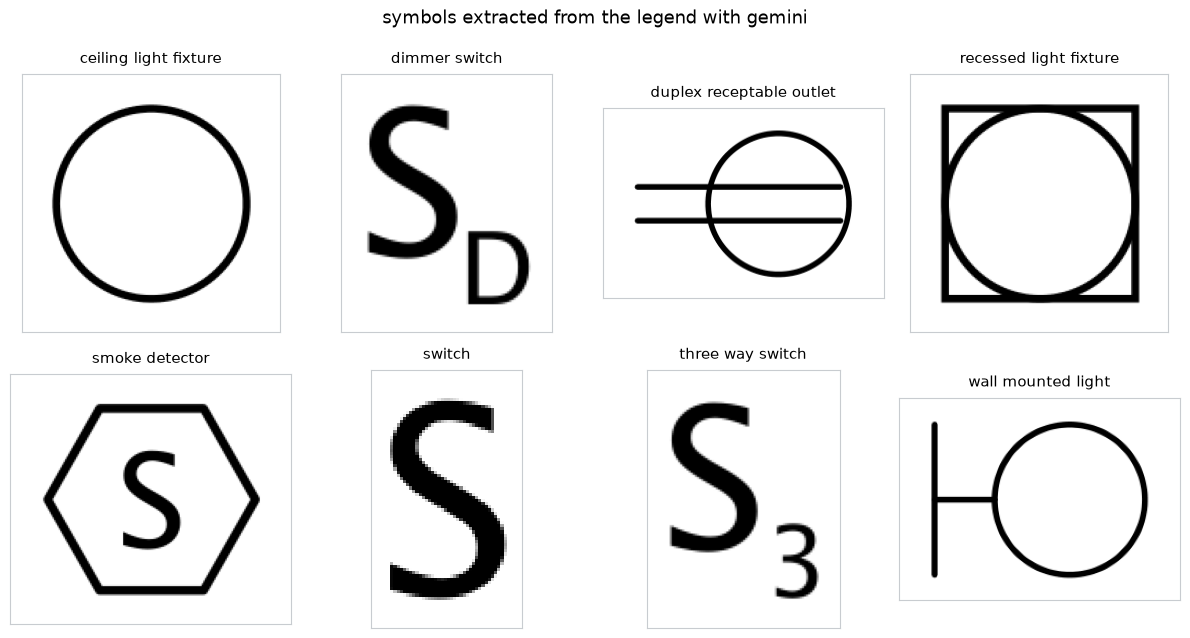

In [7]:
import os, math, cv2
import matplotlib.pyplot as plt

files = sorted(f for f in os.listdir("symbols") if f.endswith(".png"))
cols = 4
rows = math.ceil(len(files) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.2 * rows))
for ax, f in zip(axes.ravel(), files):
    img = cv2.imread(f"symbols/{f}")
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f[:-4].replace("_", " "), fontsize=11, pad=8)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("#c8ccd0")

for ax in axes.ravel()[len(files):]:
    ax.axis("off")

fig.suptitle(f"symbols extracted from the legend with gemini", fontsize=13, y=0.99)
fig.tight_layout()
fig.savefig("contact_sheet.png", dpi=300, bbox_inches="tight")
plt.show()